# Look At GPS Points

In [1]:
# setup the venv
# run this cell first, then refresh the page and select the kernel.
# there is no harm in running this after setting it up, inly a few seconds
!bash /home/hcr64/Pinyon-Detection/shells/jupyter_kernel_env.sh

Installed kernelspec open3d_env in /home/hcr64/.local/share/jupyter/kernels/open3d_env


In [2]:
import sys, os, re
import numpy as np
import pandas as pd
import open3d as o3d
from pyproj import Transformer
from scipy.spatial import cKDTree

sys.path.insert(0, "/home/hcr64/Pinyon-Detection")
from global_files import get_paths

TRIAL_NAME = "Sunset_sfm_trial"
PATHS = get_paths(TRIAL_NAME)

RADIUS      = 3.0     # metres around each GPS point (XY distance)
EXCLUSIVE   = False    # True: a point goes only to its nearest GPS label (no overlap)
SAVE        = True
OUT_DIR     = os.path.join(os.path.dirname(PATHS['Clusters'].rstrip('/')), 'gps_clusters/')

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [3]:
import numpy as np
import open3d as o3d
import plotly.graph_objects as go
from plyfile import PlyData

# distinct colours used when color_by_source=True
_PALETTE = ["#e6194b", "#3cb44b", "#4363d8", "#f58231",
            "#911eb4", "#46f0f0", "#f032e6", "#bcf60c"]

def _points_and_colors(src):
    """Return (N,3) points and (N,3) colours in 0-255 (or None) from a path or PointCloud."""
    if isinstance(src, o3d.geometry.PointCloud):
        points = np.asarray(src.points)
        # Open3D stores colours as floats in 0-1
        colors = np.asarray(src.colors) * 255 if src.has_colors() else None
    else:
        vertex = PlyData.read(str(src))["vertex"]
        points = np.vstack([vertex["x"], vertex["y"], vertex["z"]]).T
        names = vertex.data.dtype.names
        if {"red", "green", "blue"} <= set(names):
            # .ply files written by Open3D store colours as 0-255
            colors = np.vstack([vertex["red"], vertex["green"], vertex["blue"]]).T
        else:
            colors = None
    return points, colors

def visualize_pointcloud(src, point_size=2, background_color="black",
                         color_by_source=False, max_points=None):
    """
    src: a .ply path, an o3d PointCloud, or a list/tuple of either.
    color_by_source: give each item in a list one flat colour, to compare split pieces.
    max_points: randomly subsample each cloud to this many points for faster rendering.
    """
    sources = list(src) if isinstance(src, (list, tuple)) else [src]
    rng = np.random.default_rng(0)
    traces = []

    for i, s in enumerate(sources):
        points, colors = _points_and_colors(s)

        if max_points is not None and len(points) > max_points:
            keep = rng.choice(len(points), max_points, replace=False)
            points = points[keep]
            colors = colors[keep] if colors is not None else None

        if color_by_source or colors is None:
            marker_color = _PALETTE[i % len(_PALETTE)] if color_by_source else "white"
        else:
            marker_color = [f"rgb({int(r)},{int(g)},{int(b)})" for r, g, b in colors]

        traces.append(go.Scatter3d(
            x=points[:, 0], y=points[:, 1], z=points[:, 2],
            mode="markers",
            marker=dict(size=point_size, color=marker_color),
            name=f"piece {i} ({len(points)} pts)",
        ))

    fig = go.Figure(data=traces)
    fig.update_layout(scene=dict(bgcolor=background_color, aspectmode="data"),
                      paper_bgcolor="black",
                      legend=dict(font=dict(color="white")))
    fig.show() ### can you use this function to draw the slice of the pointcloud and i can look at it

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import pandas as pd

DISTANCE      = 6.0     # m, how far around each GPS point to look
MAX_DISTANCE  = 4.0     # m, the matching radius used in clustering (drawn as a ring)
STATUS_FILTER = None    # None, "no_match", or "multi"

df_bad = pd.read_csv(PATHS['Dataframes'] + 'gps_unmatched.csv')
if STATUS_FILTER:
    df_bad = df_bad[df_bad["status"] == STATUS_FILTER]
df_bad = df_bad.reset_index(drop=True)
print(df_bad["status"].value_counts())

df_cl = pd.read_csv(PATHS['Dataframes'] + 'clusters.csv')   # file, x_pos, y_pos, ...

pcd  = o3d.io.read_point_cloud(PATHS['Raw_pcd'])
pts  = np.asarray(pcd.points)
cols = np.asarray(pcd.colors)
print(f"{len(pts):,} raw points")

# indices of raw points within DISTANCE (XY) of each bad GPS point
tree = cKDTree(pts[:, :2])
bad_xy = df_bad[["x", "y"]].values
member_idx = [np.array(m, dtype=int) for m in tree.query_ball_point(bad_xy, r=DISTANCE)]
print("points per area: median", int(np.median([len(m) for m in member_idx])),
      "| empty areas:", sum(len(m) == 0 for m in member_idx))

status
no_match    45
multi       10
Name: count, dtype: int64
199,619,380 raw points
points per area: median 74611 | empty areas: 0


## Filter Fringe GPS Tags

In [5]:
MIN_COVERAGE = 0.99     # keep tags with at least this fraction of the disc covered
CELL         = 0.5      # m, occupancy grid cell size (keep >> the 0.08 m voxel size)

# occupancy grid of the whole cloud
x0, y0 = pts[:, 0].min(), pts[:, 1].min()
ncx = int((pts[:, 0].max() - x0) / CELL) + 1
ncy = int((pts[:, 1].max() - y0) / CELL) + 1
occ = np.zeros((ncx, ncy), dtype=bool)
occ[((pts[:, 0] - x0) / CELL).astype(int), ((pts[:, 1] - y0) / CELL).astype(int)] = True

# grid cell centres inside a disc of radius DISTANCE (offsets relative to the tag)
offs = np.arange(-DISTANCE, DISTANCE + CELL, CELL)
ox, oy = np.meshgrid(offs, offs)
in_disc = np.hypot(ox, oy) <= DISTANCE
ox, oy = ox[in_disc], oy[in_disc]

def coverage(gx, gy):
    ix = np.floor((gx + ox - x0) / CELL).astype(int)
    iy = np.floor((gy + oy - y0) / CELL).astype(int)
    ok = (ix >= 0) & (ix < ncx) & (iy >= 0) & (iy < ncy)   # outside the grid = uncovered
    hit = np.zeros(len(ix), dtype=bool)
    hit[ok] = occ[ix[ok], iy[ok]]
    return hit.mean()

df_bad["coverage"] = [coverage(x, y) for x, y in bad_xy]

print(df_bad["coverage"].describe().round(2))
print(f"\nBefore: {len(df_bad)}")
print(df_bad.groupby("status")["coverage"].agg(["count", "median", "min"]).round(2))

keep = (df_bad["coverage"] >= MIN_COVERAGE).values
print(f"\nDropping {(~keep).sum()} below {MIN_COVERAGE:.0%} coverage, keeping {keep.sum()}")

# filter df_bad and member_idx together so they stay aligned
df_dropped = df_bad[~keep].reset_index(drop=True)
df_bad     = df_bad[keep].reset_index(drop=True)
member_idx = [m for m, k in zip(member_idx, keep) if k]
bad_xy     = df_bad[["x", "y"]].values
print("After:", len(df_bad))

count    55.00
mean      0.95
std       0.13
min       0.32
25%       0.98
50%       1.00
75%       1.00
max       1.00
Name: coverage, dtype: float64

Before: 55
          count  median   min
status                       
multi        10     1.0  1.00
no_match     45     1.0  0.32

Dropping 15 below 99% coverage, keeping 40
After: 40


## Look at Galleries of Top Down images of points

In [6]:
PAGE, PAGE_SIZE, N_COLS = 0, 24, 4      # change PAGE to flip through


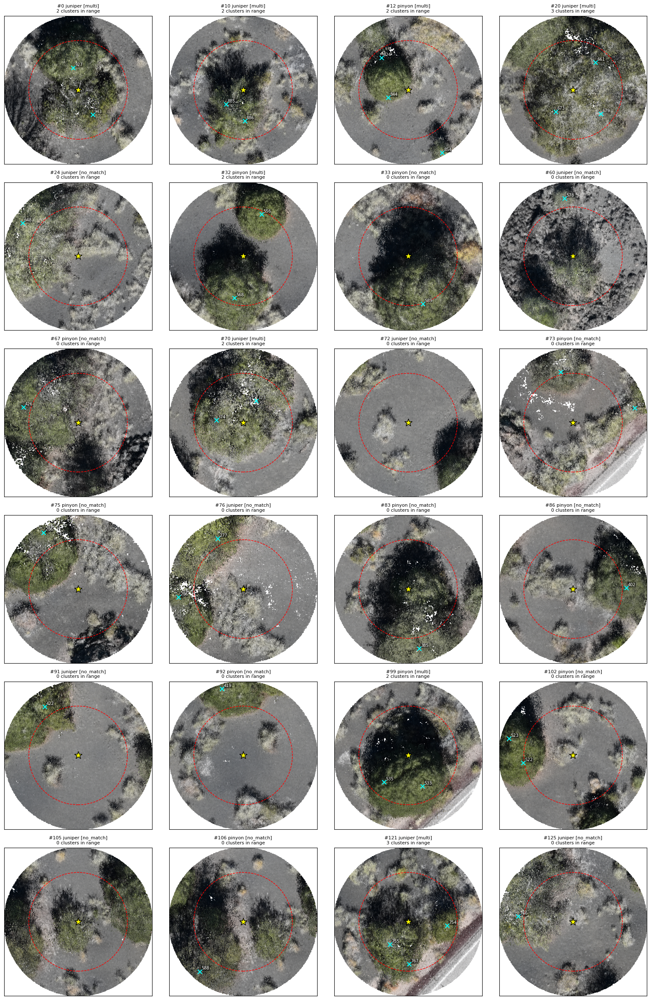

In [7]:
def draw_area(ax, i):
    row = df_bad.iloc[i]
    gx, gy = row["x"], row["y"]
    idx = member_idx[i]
    if len(idx):
        ax.scatter(pts[idx, 0], pts[idx, 1], c=cols[idx], s=2)
    ax.add_patch(Circle((gx, gy), MAX_DISTANCE, fill=False, ec="red", ls="--", lw=1))
    ax.scatter([gx], [gy], marker="*", s=180, c="yellow", ec="black", zorder=5)

    near = df_cl[np.hypot(df_cl["x_pos"] - gx, df_cl["y_pos"] - gy) <= DISTANCE]
    ax.scatter(near["x_pos"], near["y_pos"], marker="x", c="cyan", s=50, zorder=4)
    for r in near.itertuples():
        ax.annotate(int(r.file), (r.x_pos, r.y_pos), color="white", fontsize=7,
                    xytext=(3, 3), textcoords="offset points",
                    bbox=dict(fc="black", alpha=0.5, pad=0.5, lw=0))

    ax.set_xlim(gx - DISTANCE, gx + DISTANCE)
    ax.set_ylim(gy - DISTANCE, gy + DISTANCE)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"#{int(row.gps_idx)} {row.Name} [{row.status}]\n"
                 f"{int(row.n_clusters_in_range)} clusters in range", fontsize=8)

sel = range(PAGE * PAGE_SIZE, min((PAGE + 1) * PAGE_SIZE, len(df_bad)))
n_rows = int(np.ceil(len(sel) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(4 * N_COLS, 4 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, i in zip(axes, sel):
    draw_area(ax, i)
for ax in axes[len(sel):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

# iterate page for the next one
PAGE += 1

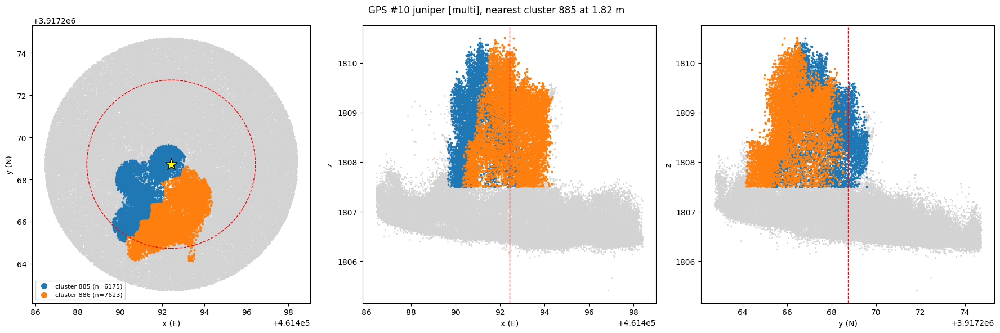

In [8]:
GPS_IDX = int(df_bad["gps_idx"].iloc[1])     # pick a gps_idx from the gallery titles

i = df_bad.index[df_bad["gps_idx"] == GPS_IDX][0]
row = df_bad.iloc[i]
gx, gy = row["x"], row["y"]
idx = member_idx[i]

# cluster files to draw: everything in range, or the nearest one for no_match points
if pd.notna(row["cluster_files_in_range"]) and row["cluster_files_in_range"] != "":
    files = [int(f) for f in str(row["cluster_files_in_range"]).split(";")]
else:
    files = [int(row["nearest_cluster_file"])]

cl_pts = {}
for f in files:
    p = PATHS['Clusters'] + f"cluster{f}.ply"
    if os.path.exists(p):
        cl_pts[f] = np.asarray(o3d.io.read_point_cloud(p).points)

palette = plt.cm.tab10.colors
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
views = [(0, 1, "x (E)", "y (N)"), (0, 2, "x (E)", "z"), (1, 2, "y (N)", "z")]

for ax, (a, b, la, lb) in zip(axs, views):
    ax.scatter(pts[idx, a], pts[idx, b], c="lightgrey", s=1)
    for k, (f, cp) in enumerate(cl_pts.items()):
        ax.scatter(cp[:, a], cp[:, b], s=3, color=palette[k % 10],
                   label=f"cluster {f} (n={len(cp)})")
    g = [gx, gy, np.nan]
    if a == 0 and b == 1:
        ax.scatter([gx], [gy], marker="*", s=250, c="yellow", ec="black", zorder=5)
        ax.add_patch(Circle((gx, gy), MAX_DISTANCE, fill=False, ec="red", ls="--"))
        ax.set_aspect("equal")
    else:
        ax.axvline(g[a], color="red", ls="--", lw=1)   # GPS position along this axis
    ax.set_xlabel(la); ax.set_ylabel(lb)

axs[0].legend(fontsize=8, markerscale=4)
fig.suptitle(f"GPS #{GPS_IDX} {row.Name} [{row.status}], "
             f"nearest cluster {row.nearest_cluster_file} at {row.nearest_cluster_dist_m} m")
plt.tight_layout()
plt.show()

## Look at The Verticle Core of Raw Pointcloud Around Clusters

In [9]:
CORE_RADIUS = 3.0      # m, XY radius of the cylinder around the tag
GPS_IDX     = int(df_bad["gps_idx"].iloc[0])
GREEN_EXG   = 0.05     # same ExG bar the pipeline's green filter implies
MATCH_TOL   = 0.05     # m, 3D tolerance for "this raw point is in that cluster"

i   = df_bad.index[df_bad["gps_idx"] == GPS_IDX][0]
row = df_bad.iloc[i]
gx, gy = row["x"], row["y"]

core_idx = np.array(tree.query_ball_point([gx, gy], r=CORE_RADIUS), dtype=int)
cp, cc = pts[core_idx], cols[core_idx]
ground_z = np.percentile(cp[:, 2], 5)
height   = cp[:, 2] - ground_z                       # height above local ground proxy
exg      = 2 * cc[:, 1] - cc[:, 0] - cc[:, 2]
is_green = exg >= GREEN_EXG

# which saved cluster (if any) each core point belongs to
near_cl = df_cl[np.hypot(df_cl["x_pos"] - gx, df_cl["y_pos"] - gy) <= CORE_RADIUS + 6]
member = np.full(len(cp), -1)                        # -1 = in no cluster
cl_clouds = {}
for f in near_cl["file"].astype(int):
    p = PATHS['Clusters'] + f"cluster{f}.ply"
    if not os.path.exists(p):
        continue
    c_pts = np.asarray(o3d.io.read_point_cloud(p).points)
    cl_clouds[f] = c_pts
    d, _ = cKDTree(c_pts).query(cp, distance_upper_bound=MATCH_TOL)
    member[np.isfinite(d)] = f

print(f"GPS #{GPS_IDX} {row.Name} [{row.status}]  core radius {CORE_RADIUS} m")
print(f"  points in core:        {len(cp):,}")
print(f"  z range:               {cp[:,2].min():.2f} to {cp[:,2].max():.2f}  "
      f"(height above ground proxy: max {height.max():.2f} m)")
print(f"  green (ExG>={GREEN_EXG}):  {is_green.sum():,}  ({100*is_green.mean():.1f}%)")
print(f"  in no cluster:         {(member == -1).sum():,}  ({100*(member == -1).mean():.1f}%)")

summary = []
for f in sorted(cl_clouds):
    m = member == f
    summary.append({"cluster": f, "core_points": int(m.sum()),
                    "cluster_total": len(cl_clouds[f]),
                    "pct_of_cluster_in_core": round(100 * m.sum() / len(cl_clouds[f]), 1),
                    "pct_green": round(100 * is_green[m].mean(), 1) if m.any() else np.nan,
                    "max_height_m": round(float(height[m].max()), 2) if m.any() else np.nan})
print(pd.DataFrame(summary).to_string(index=False))

GPS #0 juniper [multi]  core radius 3.0 m
  points in core:        29,493
  z range:               1808.85 to 1813.62  (height above ground proxy: max 4.05 m)
  green (ExG>=0.05):  18,055  (61.2%)
  in no cluster:         5,743  (19.5%)
 cluster  core_points  cluster_total  pct_of_cluster_in_core  pct_green  max_height_m
     927        17136          19087                    89.8       70.6          4.05
     943         6614           6711                    98.6       75.7          4.05


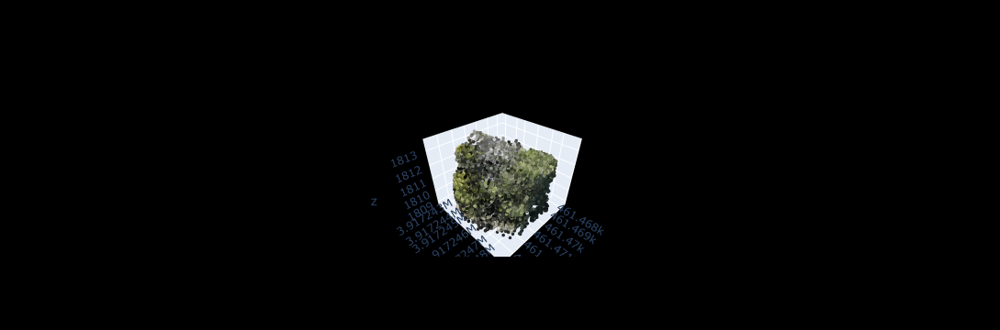

{0: 'no cluster', 1: 'cluster 927', 2: 'cluster 943'}


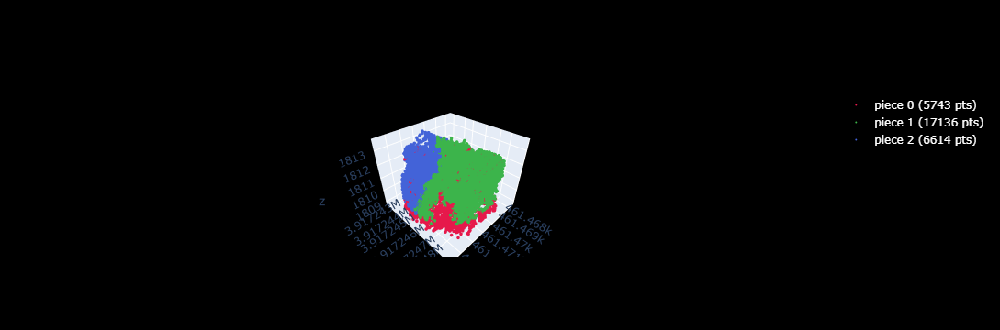

In [10]:
def make_pcd(idx):
    p = o3d.geometry.PointCloud()
    p.points = o3d.utility.Vector3dVector(pts[idx])
    p.colors = o3d.utility.Vector3dVector(cols[idx])
    return p

core_pcd = make_pcd(core_idx)
visualize_pointcloud(core_pcd, point_size=2, max_points=60000)

pieces = [make_pcd(core_idx[member == -1])]               # piece 0: in no cluster
labels = ["no cluster"]
for f in sorted(cl_clouds):
    m = member == f
    if m.any():
        pieces.append(make_pcd(core_idx[m]))
        labels.append(f"cluster {f}")

print(dict(enumerate(labels)))   # piece number -> meaning
visualize_pointcloud(pieces, point_size=2, color_by_source=True, max_points=40000)

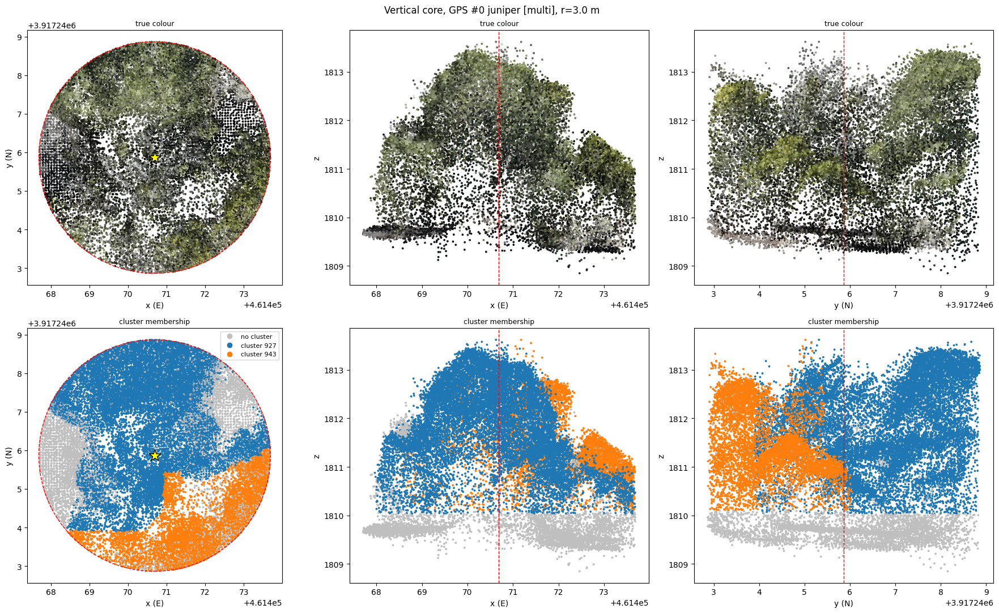

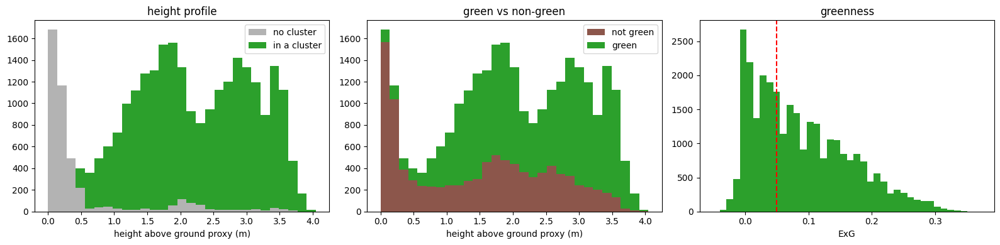

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

palette = plt.cm.tab10.colors
member_ids = sorted(cl_clouds)
member_col = np.array([(0.75, 0.75, 0.75)] * len(cp))
for k, f in enumerate(member_ids):
    member_col[member == f] = palette[k % 10]

views = [(0, 1, "x (E)", "y (N)"), (0, 2, "x (E)", "z"), (1, 2, "y (N)", "z")]
fig, axs = plt.subplots(2, 3, figsize=(18, 11))

for r, (colors, label) in enumerate([(cc, "true colour"), (member_col, "cluster membership")]):
    for ax, (a, b, la, lb) in zip(axs[r], views):
        ax.scatter(cp[:, a], cp[:, b], c=colors, s=3)
        if (a, b) == (0, 1):
            ax.scatter([gx], [gy], marker="*", s=250, c="yellow", ec="black", zorder=5)
            ax.add_patch(Circle((gx, gy), CORE_RADIUS, fill=False, ec="red", ls="--"))
            ax.set_aspect("equal")
        else:
            ax.axvline([gx, gy][a], color="red", ls="--", lw=1)   # tag position on this axis
        ax.set_xlabel(la); ax.set_ylabel(lb); ax.set_title(label, fontsize=9)

handles = [plt.Line2D([], [], marker="o", ls="", color="0.75", label="no cluster")]
handles += [plt.Line2D([], [], marker="o", ls="", color=palette[k % 10],
                       label=f"cluster {f}") for k, f in enumerate(member_ids)]
axs[1, 0].legend(handles=handles, fontsize=8)
fig.suptitle(f"Vertical core, GPS #{GPS_IDX} {row.Name} [{row.status}], r={CORE_RADIUS} m")
plt.tight_layout()
plt.show()

# height profile: what the core holds at each height, split by cluster / non-cluster / green
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
bins = np.linspace(0, max(height.max(), 1), 30)
axs[0].hist([height[member == -1], height[member != -1]], bins=bins, stacked=True,
            color=["0.7", "tab:green"], label=["no cluster", "in a cluster"])
axs[0].set_xlabel("height above ground proxy (m)"); axs[0].legend(); axs[0].set_title("height profile")
axs[1].hist([height[~is_green], height[is_green]], bins=bins, stacked=True,
            color=["tab:brown", "tab:green"], label=["not green", "green"])
axs[1].set_xlabel("height above ground proxy (m)"); axs[1].legend(); axs[1].set_title("green vs non-green")
axs[2].hist(exg, bins=40, color="tab:green")
axs[2].axvline(GREEN_EXG, color="red", ls="--"); axs[2].set_xlabel("ExG"); axs[2].set_title("greenness")
plt.tight_layout()
plt.show()

## (NOT USED)Look at the new area clusters

In [12]:
ind = 3

In [13]:
# plotly version
ind += 1
import plotly.graph_objects as go
c = gps_clusters[ind]
p = np.asarray(c.points)
col = (np.asarray(c.colors) * 255).astype(int) if c.has_colors() else None
fig = go.Figure(go.Scatter3d(
    x=p[:, 0], y=p[:, 1], z=p[:, 2], mode="markers",
    marker=dict(size=1.5, color=[f"rgb({r},{g},{b})" for r, g, b in col] if col is not None else None)))
fig.update_scenes(aspectmode="data")
fig.show()

NameError: name 'gps_clusters' is not defined

In [ ]:
# doesn't work view one cluster
o3d.visualization.draw_geometries([gps_clusters[3]])